In [2]:
from matplotlib import pyplot as plt
import numpy as np

In [3]:
x = np.linspace(-1.0, 1.0, 21)
y = np.cos(x * np.pi/2) + 0.2 * np.random.randn(21)

x, y

(array([-1. , -0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1,  0. ,
         0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ]),
 array([-0.0664489 ,  0.2567072 ,  0.41251839,  0.19236497,  0.60438423,
         0.4389186 ,  1.00831728,  0.62800711,  0.87157239,  0.48809593,
         0.84379051,  1.38161969,  1.35340838,  0.96912911,  0.78324821,
         0.97578528,  0.76497557,  0.24190513,  0.07455468, -0.17762851,
         0.09190262]))

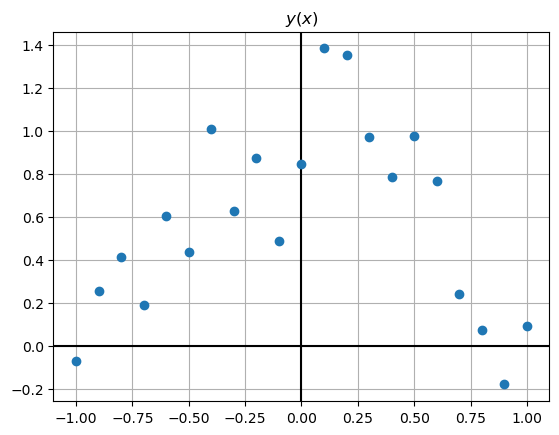

In [4]:
plt.grid(True); plt.axhline(0.0, c='k'); plt.axvline(0.0, c='k')
plt.plot(x, y, 'o')
plt.title('$y(x)$')
plt.show()

In [5]:
X = np.array([x ** 2, x, np.ones_like(x)]).T

X

array([[ 1.  , -1.  ,  1.  ],
       [ 0.81, -0.9 ,  1.  ],
       [ 0.64, -0.8 ,  1.  ],
       [ 0.49, -0.7 ,  1.  ],
       [ 0.36, -0.6 ,  1.  ],
       [ 0.25, -0.5 ,  1.  ],
       [ 0.16, -0.4 ,  1.  ],
       [ 0.09, -0.3 ,  1.  ],
       [ 0.04, -0.2 ,  1.  ],
       [ 0.01, -0.1 ,  1.  ],
       [ 0.  ,  0.  ,  1.  ],
       [ 0.01,  0.1 ,  1.  ],
       [ 0.04,  0.2 ,  1.  ],
       [ 0.09,  0.3 ,  1.  ],
       [ 0.16,  0.4 ,  1.  ],
       [ 0.25,  0.5 ,  1.  ],
       [ 0.36,  0.6 ,  1.  ],
       [ 0.49,  0.7 ,  1.  ],
       [ 0.64,  0.8 ,  1.  ],
       [ 0.81,  0.9 ,  1.  ],
       [ 1.  ,  1.  ,  1.  ]])

In [6]:
theta = np.linalg.inv(X.T @ X) @ (X.T @ y)

theta

array([-1.09283442,  0.01228224,  0.97866442])

In [7]:
y_hat = X @ theta

y_hat

array([-0.12645223,  0.08241453,  0.26942461,  0.43457799,  0.57787469,
        0.6993147 ,  0.79889802,  0.87662466,  0.9324946 ,  0.96650786,
        0.97866442,  0.9689643 ,  0.93740749,  0.883994  ,  0.80872381,
        0.71159694,  0.59261338,  0.45177313,  0.28907619,  0.10452256,
       -0.10188776])

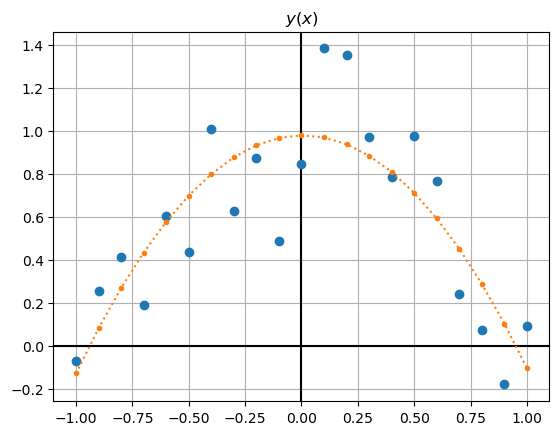

In [8]:
plt.grid(True); plt.axhline(0.0, c='k'); plt.axvline(0.0, c='k')
plt.plot(x, y, 'o')
plt.plot(x, y_hat, ':.')
plt.title('$y(x)$')
plt.show()

In [9]:
error = y_hat - y
cost = 0.5 * np.mean(error ** 2)

cost

np.float64(0.028477337127783914)

In [10]:
alpha = 1.0
costs = []
theta = np.zeros(X.shape[1])
for _ in range(100):
    y_hat = X @ theta
    error = y_hat - y
    theta -= alpha / y.size * (X.T @ error)
    cost = 0.5 * np.mean(error ** 2)
    costs.append(cost)
    
theta

array([-1.09276093,  0.01228224,  0.97863471])

# scikit learn

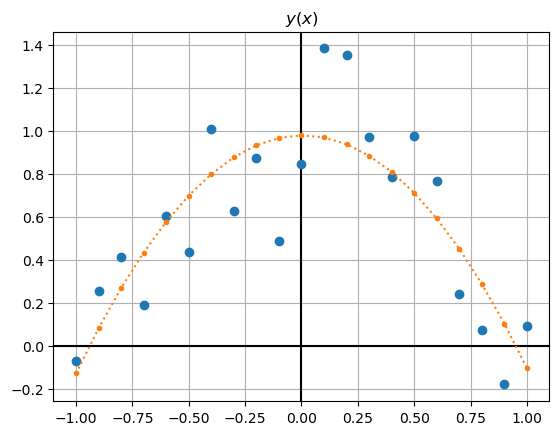

In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X[:, :-1], y)

model.coef_, model.intercept_

model = LinearRegression(fit_intercept=False)
model.fit(X, y)

model.coef_

y_hat = model.predict(X)

y_hat

plt.grid(True); plt.axhline(0.0, c='k'); plt.axvline(0.0, c='k')
plt.plot(x, y, 'o')
plt.plot(x, y_hat, ':.')
plt.title('$y(x)$')
plt.show()

In [ ]:
X = np.vander(x, 15)

X

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split

data = pd.DataFrame({
    "Age_Group": [
        "Young", "Young", "Middle", "Old", "Old",
        "Middle", "Young", "Old", "Middle", "Young",
        "Old", "Middle", "Young", "Old", "Middle"
    ],
    "Fever": [
        "No", "Yes", "Yes", "Yes", "No",
        "No", "No", "Yes", "Yes", "Yes",
        "Yes", "No", "No", "No", "Yes"
    ],
    "Cough": [
        "No", "Yes", "Yes", "Yes", "No",
        "No", "Yes", "Yes", "No", "Yes",
        "No", "Yes", "No", "Yes", "Yes"
    ],
    "Class": [
        "Healthy", "Mild", "Severe", "Severe", "Healthy",
        "Healthy", "Mild", "Severe", "Mild", "Mild",
        "Mild", "Mild", "Healthy", "Severe", "Severe"
    ]
})

X = data.drop("Class", axis=1)
y = data["Class"]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [14]:
X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)

# Ensure both datasets have exactly the same columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

In [15]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train_encoded, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [16]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_encoded)

print("Predictions:")
print(y_pred)

print("\nActual classes:")
print(y_test.values)

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Predictions:
['Severe' 'Healthy' 'Healthy' 'Severe' 'Healthy']

Actual classes:
['Severe' 'Mild' 'Healthy' 'Severe' 'Mild']

Accuracy:
0.6

Classification report:
              precision    recall  f1-score   support

     Healthy       0.33      1.00      0.50         1
        Mild       0.00      0.00      0.00         2
      Severe       1.00      1.00      1.00         2

    accuracy                           0.60         5
   macro avg       0.44      0.67      0.50         5
weighted avg       0.47      0.60      0.50         5



In [17]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

y_train_onehot = encoder.fit_transform(y_train.to_frame())
y_test_onehot = encoder.transform(y_test.to_frame())

print(y_train_onehot)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


# or

In [20]:
def train_test_split(X, y, test_size=0.3, random_state=42):
    np.random.seed(random_state)

    indices = np.random.permutation(len(X))
    test_count = int(len(X) * test_size)

    test_indices = indices[:test_count]
    train_indices = indices[test_count:]

    return (
        X.iloc[train_indices],
        X.iloc[test_indices],
        y.iloc[train_indices],
        y.iloc[test_indices]
    )


X = data.drop("Class", axis=1)
y = data["Class"]

X_train, X_test, y_train, y_test = train_test_split(X, y)

def one_hot_encode(X_train, X_test):
    X_train_encoded = pd.get_dummies(X_train, dtype=int)
    X_test_encoded = pd.get_dummies(X_test, dtype=int)

    X_test_encoded = X_test_encoded.reindex(
        columns=X_train_encoded.columns,
        fill_value=0
    )

    return X_train_encoded, X_test_encoded


X_train, X_test = one_hot_encode(X_train, X_test)

def entropy(y):
    probabilities = y.value_counts(normalize=True)

    return -sum(
        p * np.log2(p)
        for p in probabilities
    )

def information_gain(data, feature, target):
    initial_entropy = entropy(data[target])

    weighted_entropy = 0

    for value in data[feature].unique():
        subset = data[data[feature] == value]

        weight = len(subset) / len(data)

        weighted_entropy += weight * entropy(subset[target])

    return initial_entropy - weighted_entropy

def id3(data, features, target):

    y = data[target]

    # Majority class
    majority_class = y.mode().iloc[0]

    # Stop if all observations have the same class
    if y.nunique() == 1:
        return y.iloc[0]

    # Stop if there are no remaining features
    if len(features) == 0:
        return majority_class

    # Calculate information gain for each feature
    gains = {
        feature: information_gain(data, feature, target)
        for feature in features
    }

    # Select the feature with the highest information gain
    best_feature = max(gains, key=gains.get)

    # Stop if no useful split is available
    if gains[best_feature] <= 0:
        return majority_class

    tree = {best_feature: {}}

    remaining_features = [
        feature for feature in features
        if feature != best_feature
    ]

    # Create branches
    for value in data[best_feature].unique():

        subset = data[data[best_feature] == value]

        tree[best_feature][value] = id3(
            subset,
            remaining_features,
            target
        )

    return tree

In [21]:
train_data = X_train.copy()
train_data["Class"] = y_train

features = list(X_train.columns)

tree = id3(train_data, features, "Class")

print(tree)

{'Fever_No': {np.int64(1): {'Cough_No': {np.int64(1): 'Healthy', np.int64(0): 'Mild'}}, np.int64(0): {'Cough_No': {np.int64(1): 'Mild', np.int64(0): {'Age_Group_Young': {np.int64(0): 'Severe', np.int64(1): 'Mild'}}}}}}


In [22]:
def predict_one(tree, sample):

    # If the current node is a class label, return it
    if not isinstance(tree, dict):
        return tree

    feature = next(iter(tree))

    value = sample[feature]

    # Follow the corresponding branch
    if value in tree[feature]:
        return predict_one(tree[feature][value], sample)

    # Fallback for an unknown branch
    return None

In [23]:
def predict(tree, X_test):
    predictions = []

    for _, sample in X_test.iterrows():
        predictions.append(predict_one(tree, sample))

    return predictions


y_pred = predict(tree, X_test)

print("Predictions:", y_pred)
print("Actual:", y_test.tolist())

Predictions: ['Mild', 'Mild', 'Healthy', 'Mild']
Actual: ['Mild', 'Mild', 'Healthy', 'Severe']


In [24]:
def accuracy(y_true, y_pred):

    correct = sum(
        actual == predicted
        for actual, predicted in zip(y_true, y_pred)
    )

    return correct / len(y_true)


print("Accuracy:", accuracy(y_test.tolist(), y_pred))

Accuracy: 0.75
